# Home Credit Default Risk — Model Comparison

This notebook evaluates and compares the 5 trained classifiers: XGBoost, LightGBM, MLP, Entity Embedding Network (EEN), and TabTransformer.
We will compute comparative ROC curves, Precision-Recall curves, calibration diagnostics, and run statistical significance tests.

## 1. Setup & Imports

In [1]:
import os
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Append parent directory to path to enable src imports
sys.path.append("..")
# Change working directory to project root so relative paths work
os.chdir("..")

from src.models.train import load_data
from src.evaluation.metrics import compute_all_metrics, wilcoxon_test
from src.evaluation.plots import plot_roc_curves, plot_pr_curves, plot_calibration_curves

%matplotlib inline
sns.set_theme(style="whitegrid")

## 2. Load Evaluation Data & Models
We load the test split of our dataset.

In [2]:
_, _, _, _, X_test, y_test = load_data()
print(f"Test set size: {X_test.shape[0]} samples")

Loading existing split indices from data/splits...
Dataset splits loaded successfully:
  Train: X=(400, 77), y=(400,), positive_rate=7.00%
  Val:   X=(50, 77), y=(50,), positive_rate=12.00%
  Test:  X=(50, 77), y=(50,), positive_rate=10.00%
Test set size: 50 samples


## 3. Load Models & Generate Probabilities
We query the best MLflow runs and load the fitted models.

In [3]:
import mlflow
from mlflow.tracking import MlflowClient

mlflow.set_tracking_uri("mlruns")
client = MlflowClient()

model_types = ["xgboost", "lgbm", "mlp", "entity_embedding", "tab_transformer"]
predictions = {}
results = {}

experiments = client.search_experiments()
exp_ids = [e.experiment_id for e in experiments]

for m_type in model_types:
    runs = client.search_runs(
        experiment_ids=exp_ids,
        filter_string=f"tags.model_type = '{m_type}'",
        order_by=["metrics.test_roc_auc DESC"],
        max_results=1
    )
    if runs:
        run_id = runs[0].info.run_id
        ext = ".pt" if m_type in ["mlp", "entity_embedding", "tab_transformer"] else ".pkl"
        model_path = os.path.join("mlflow_artifacts", f"model_{m_type}_{run_id}{ext}")
        
        if os.path.exists(model_path):
            if m_type == "xgboost":
                from src.models.xgboost_model import XGBoostModel
                model = XGBoostModel.load(model_path)
            elif m_type == "lgbm":
                from src.models.lgbm_model import LGBMModel
                model = LGBMModel.load(model_path)
            elif m_type == "mlp":
                from src.models.mlp import MLPModel
                model = MLPModel.load(model_path)
            elif m_type == "entity_embedding":
                from src.models.entity_embedding import EntityEmbeddingModel
                model = EntityEmbeddingModel.load(model_path)
            elif m_type == "tab_transformer":
                from src.models.tab_transformer import TabTransformerModel
                model = TabTransformerModel.load(model_path)
                
            probs = model.predict_proba(X_test)
            predictions[m_type] = probs
            results[m_type] = compute_all_metrics(y_test.values, probs)
            print(f"Loaded & evaluated {m_type} (Test AUC: {results[m_type]['roc_auc']:.4f})")

Loaded & evaluated xgboost (Test AUC: 0.6133)
Loaded & evaluated lgbm (Test AUC: 0.5067)
Loaded & evaluated mlp (Test AUC: 0.2356)


Loaded & evaluated entity_embedding (Test AUC: 0.5556)
Loaded & evaluated tab_transformer (Test AUC: 0.4089)


## 4. Performance Summary

In [4]:
df_results = pd.DataFrame(results).T
df_results.index.name = "Model"
df_results

,roc_auc,ks_stat,brier_score,calibration_slope
Model,,,,
xgboost,0.613333,0.377778,0.099599,-0.764278
lgbm,0.506667,0.266667,0.089738,0.651488
mlp,0.235556,0.533333,0.208920,-0.967142
entity_embedding,0.555556,0.377778,0.118673,1.016900
tab_transformer,0.408889,0.400000,0.270585,-1.862477


## 5. Visualizations

Saved ROC curves to reports/roc_curves.png


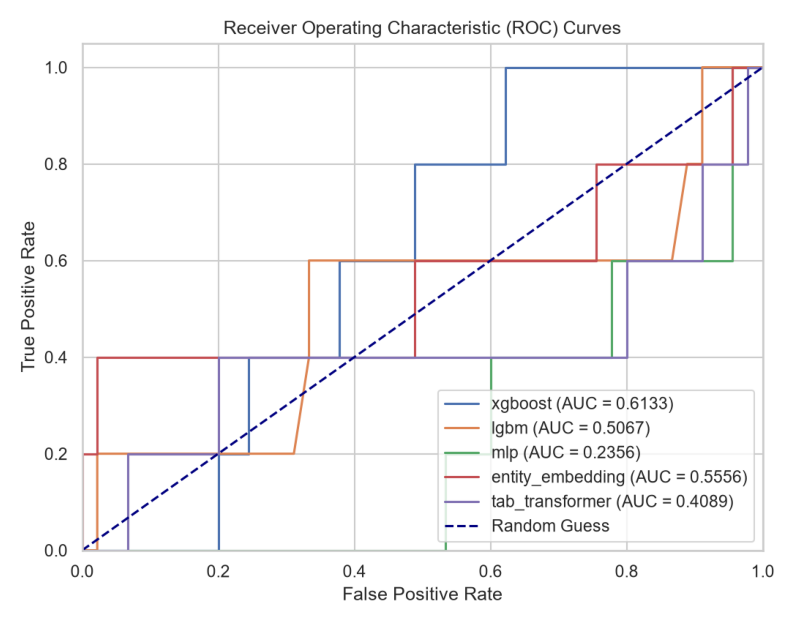

In [5]:
# Render ROC curves
os.makedirs("reports", exist_ok=True)
plot_roc_curves(y_test.values, predictions, "reports/roc_curves.png")

# Show plot
img = plt.imread("reports/roc_curves.png")
plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

Saved PR curves to reports/pr_curves.png


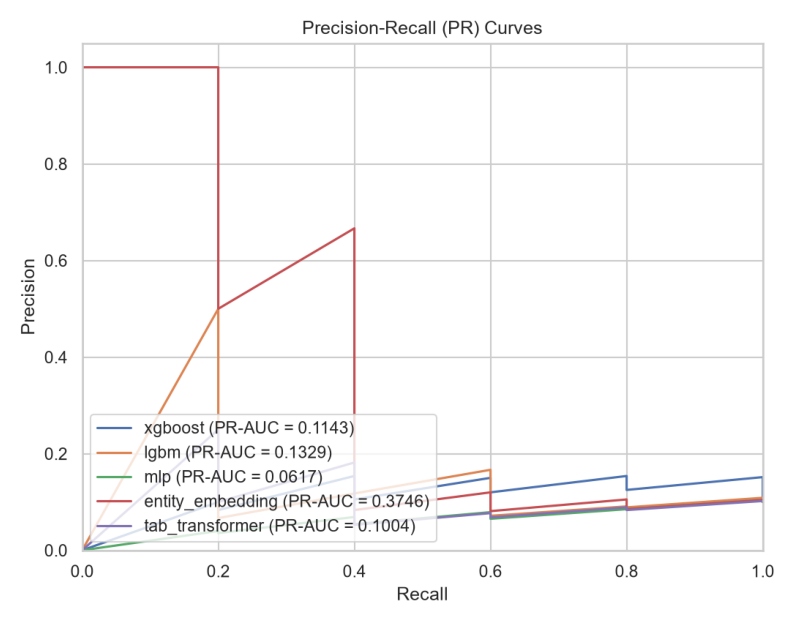

In [6]:
# Render PR curves
plot_pr_curves(y_test.values, predictions, "reports/pr_curves.png")

img = plt.imread("reports/pr_curves.png")
plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()

Saved calibration curves to reports/calibration_curves.png


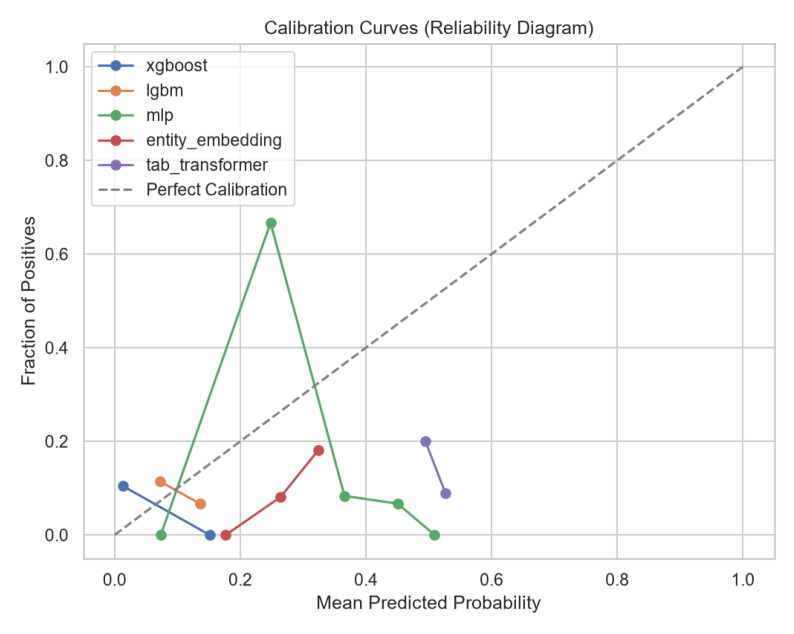

In [7]:
# Render Calibration curves
plot_calibration_curves(y_test.values, predictions, "reports/calibration_curves.png")

img = plt.imread("reports/calibration_curves.png")
plt.figure(figsize=(10, 8))
plt.imshow(img)
plt.axis("off")
plt.show()